### Discovery

Welcome new data analyst contractor, to Fictional Care Co. Whilst on your generous and extremely interesting 30 second induction, your IT systems have been fully set up, tested and everything is working perfectly. <br><br>
As your first task, you will be trying to determine if there is a linear relationship between patient characteristics and their cholesterol levels for patients living with diabetes. You will use a linear regression model to establish if any relationship exists and if so, how cholesterol levels vary by patient. Data has already been sourced by the ever efficient and humble management team. You can find a full breakdown of the fields contained within the dataset below:

--- 
### Data preparation


First we will import the required modules. They are:
- Pandas
- Seaborn
- Statsmodels.api
- Sklearn.model_selection - train_test_split

In [58]:
# Import required modules
import pandas as pd # Used for manipulating data
import seaborn as sns # Visualisations
import statsmodels.api as sm # One of the ML libraries
from sklearn.model_selection import train_test_split # Another ML library
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import matplotlib.pyplot as plt # Another viz library

Import the diabetes dataset and validate the results. 

In [59]:
# Import the first dataset and set the date as the index
diabetes_df = pd.read_csv("diabetes.csv")
diabetes_df

,Age,Gender,BMI,SBP,DBP,FPG,Chol,Tri,HDL,LDL,ALT,BUN,CCR,FFPG,smoking,drinking,family_histroy,Diabetes
0,26,1,20.1,119,81,5.80,4.36,0.86,0.90,2.43,12.0,5.40,63.8,5.40,3.000000,3.000000,0,0
1,40,1,17.7,97,54,4.60,3.70,1.02,1.50,2.04,9.2,3.70,70.3,4.10,1.000000,1.000000,0,0
2,40,2,19.7,85,53,5.30,5.87,1.29,1.75,3.37,10.1,4.10,61.1,4.85,3.000000,3.000000,0,0
3,43,1,23.1,111,71,4.50,4.05,0.74,1.27,2.60,36.5,4.38,73.4,5.30,2.000000,3.000000,0,0
4,36,1,26.5,130,82,5.54,6.69,3.49,0.91,3.64,69.3,3.86,67.5,5.53,3.000000,3.000000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4298,54,1,23.4,126,75,6.82,5.00,1.50,1.24,2.98,8.0,3.50,77.0,6.70,1.000000,3.000000,0,1
4299,50,2,22.3,115,84,5.32,4.37,2.09,1.37,2.29,21.2,4.40,47.3,6.55,4.860753,4.860753,0,1
4300,67,1,24.6,138,81,4.85,3.89,1.38,1.14,2.17,18.1,4.73,70.6,6.80,3.000000,3.000000,0,1
4301,60,2,29.0,101,60,6.70,5.91,1.29,1.73,2.85,18.9,7.33,50.2,7.00,3.000000,3.000000,0,1


In [ ]:
# Here I'm extracting the first 500 rows, using the Age and Cholesterol columns only
diabetes_df = diabetes_df[["Age","Chol"]]
diabetes_df = diabetes_df.iloc[0:500]
diabetes_df.tail()
diabetes_df.count()

Age     4303
Chol    4303
dtype: int64

In [61]:
diabetes_df.head()

,Age,Chol
0,26,4.36
1,40,3.70
2,40,5.87
3,43,4.05
4,36,6.69


In [62]:
diabetes_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4303 entries, 0 to 4302
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     4303 non-null   int64  
 1   Chol    4303 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 67.4 KB


--- 
### Model planning
You will now need to understand which variables have a relationship from the prepared data. Identifying the strength and direction of the relationships will help you to build a useful model, within the remit of the task. <br><br>
Create a correlation matrix, to establish which variables you wish to use. We will only use 1 indepednent and 1 depedant variable for this model. 

In [63]:
age_corr = diabetes_df.corr()
age_corr

,Age,Chol
Age,1.000000,0.242679
Chol,0.242679,1.000000


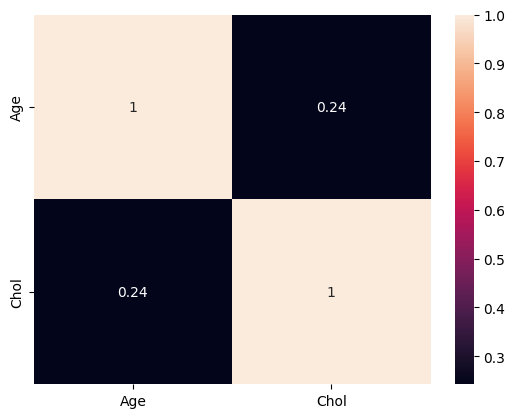

In [64]:
sns.heatmap(data = age_corr, annot=True)
plt.show()

Strip out some of the values from the dataset, I want to include the following columns:
- Chol
- Age
- Tri
- LDL

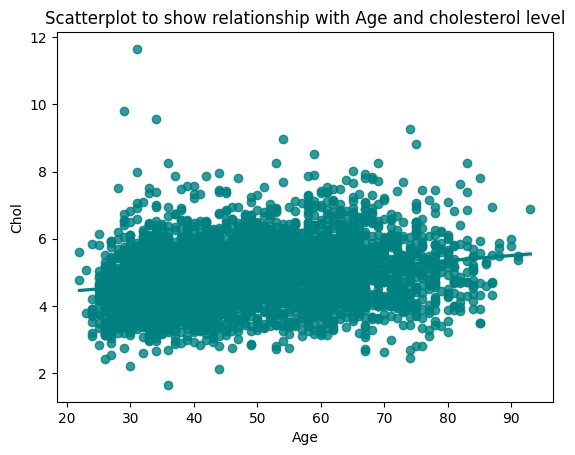

In [65]:
sns.regplot(data=diabetes_df,
                     x = "Age",
                     y = "Chol",
                     color = "teal")

plt.title("Scatterplot to show relationship with Age and cholesterol level")
plt.show()

---
### Building the model
Split the data into training and test datasets - include the random_state argument:<br>
random_state = 25

In [66]:
# Split the data into train and test samples
train, test = train_test_split(diabetes_df, random_state=10)
train.head()

,Age,Chol
1843,43,6.10
3138,66,4.53
1489,33,4.58
628,42,4.00
1133,37,3.61


Set both the independent variable and dependent variable - remember to check they are set correctly. Don't forget to add a constant to your independent variables. 

In [67]:
# Set the dependent variable and validate
dep = train[["Chol"]]
dep.head()

,Chol
1843,6.10
3138,4.53
1489,4.58
628,4.00
1133,3.61


In [68]:
# Set the independent variable and validate
ind = train[["Age"]]
ind.head()

,Age
1843,43
3138,66
1489,33
628,42
1133,37


In [69]:
# Remember to add the constant and validate
ind = sm.add_constant(ind)
ind.head()

,const,Age
1843,1.0,43
3138,1.0,66
1489,1.0,33
628,1.0,42
1133,1.0,37


Now generate the model along with a summary output. 

In [70]:
# Fit the model and produce the summary
model = sm.OLS(dep,ind).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   Chol   R-squared:                       0.053
Model:                            OLS   Adj. R-squared:                  0.053
Method:                 Least Squares   F-statistic:                     181.0
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           3.55e-40
Time:                        12:08:29   Log-Likelihood:                -4202.2
No. Observations:                3227   AIC:                             8408.
Df Residuals:                    3225   BIC:                             8420.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.1552      0.054     77.198      0.000       4.050       4.261
Age            0.0144      0.001     13.452      0.000       0.012       0.017
==============================================================================
Omnibus:                      319.530   Durbin-Watson:                   2.007
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              721.730
Skew:                           0.603   Prob(JB):                    1.90e-157
Kurtosis:                       4.978   Cond. No.                         172.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

--- 
### Communicating the results. 
You will now analyse the model and communicate the results. What do the following outputs tell you about the model

- R-Squared: 
- F-Statistic: 
- Prob (F-Statistic):
- P-Value:
- Coefficient:
- Constant:

Now lets test the model output - remember to add a constant to your test data. 

In [71]:
# Set the test sample independent variable and use the model to predict the variable, using the test dataset 
test_ind = test[["Age"]]
test_dep = test[["Chol"]]
test_ind = sm.add_constant(test_ind)


print(test_dep.shape)
print(test_ind.shape)

(1076, 1)
(1076, 2)


In [72]:
# Add the predicted values to our test dataframe to compare actual with predicted. 
test["predicted"] = model.predict(test_ind)
test[["Age","Chol","predicted"]]

,Age,Chol,predicted
3318,63,4.10,5.064020
2904,32,5.29,4.616847
2971,37,4.97,4.688972
605,38,5.18,4.703397
1610,33,3.67,4.631272
...,...,...,...
37,68,6.57,5.136145
3341,77,4.63,5.265969
1877,37,5.43,4.688972
1175,36,4.81,4.674547


With the predicted values, to compare against what actual values, we can calculate some additional statistics to validate the quality of our model.
- RMSE - the square root of the average of squared prediction errors, which shows how far predictions are from actual values with bigger mistakes weighted more heavily.
- MAPE - the average percentage difference between predicted and actual values, which shows prediction error in percent terms.
- MAE - the average of the absolute prediction errors, which shows the typical size of mistakes without caring whether they are above or below the actual values.
- MSE - the average of squared prediction errors, which shows overall error while giving extra weight to larger mistakes.

In [73]:
print(root_mean_squared_error(test["Chol"],test["predicted"]))

0.9212762804228392


In [74]:
print(mean_absolute_percentage_error(test["Chol"],test["predicted"]))

0.14830364282116368


In [75]:
print(mean_absolute_error(test["Chol"],test["predicted"]))

0.7069364448282469


In [76]:
print(mean_squared_error(test["Chol"],test["predicted"]))

0.8487499848697418


We can go further than this if we wanted to, and measure the actual values against the predicted to see how well they align. Additionally, we might like to plot residuals to see the dispersion of outliers. Outliers close to zero are preferred, with a normal distribution. 

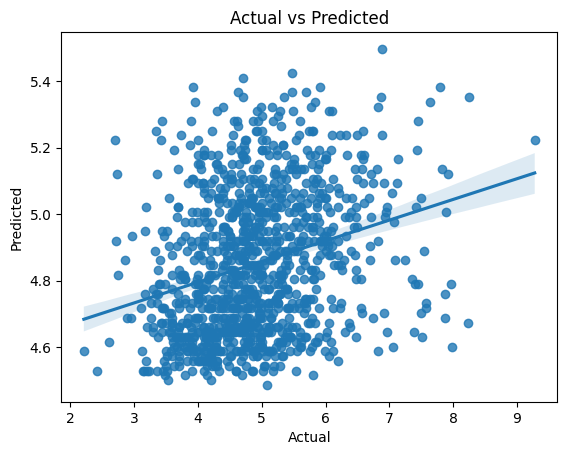

In [77]:
# Plot the actual, compared with predicted. 
# Should be on a 45° incline to show good predictions.
import matplotlib.pyplot as plt
sns.regplot(x="Chol", y="predicted", data = test)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

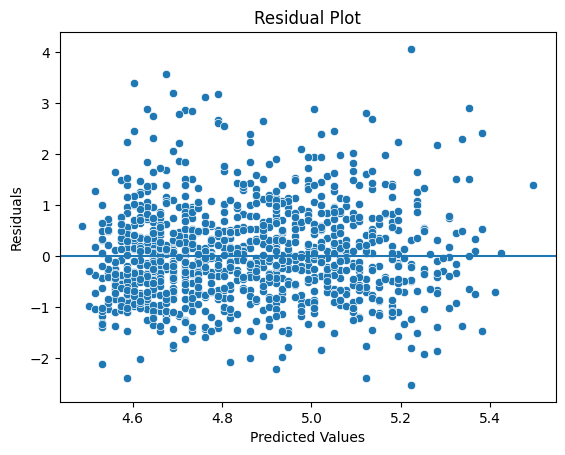

In [78]:
# Plot redsiduals to understand dispersion of outliers.
# Should be centered around 0

residuals = test["Chol"] - test["predicted"]
sns.scatterplot(x=test["predicted"], y=residuals, data = test)

plt.axhline(0)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()



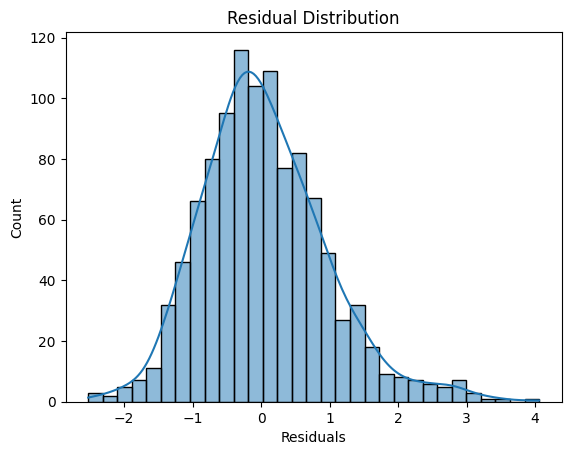

In [79]:
# Plot the distribution of residuals 
# Should look like a bell-curve when correct
sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution")

plt.show()

Finally, add a predicted column to your test dataset, where you have your prediction shown, alongside your actual values for your dependent variable. 

In [80]:
test.head()

,Age,Chol,predicted
3318,63,4.10,5.064020
2904,32,5.29,4.616847
2971,37,4.97,4.688972
605,38,5.18,4.703397
1610,33,3.67,4.631272


Now you have genereated some predictions with the test data, explain the output by way of the formula Y = mX + C

---
### Stretch task
Create a new dataframe with some example data, and generate some predictions using your model.

--- 

In [81]:
# Create a new dataframe

In [82]:
# Generate predictions

In [83]:
# Generate results in the dataframe based on new dataset

--- 
### Operationalise
In the real world, this is where you would draft a report, deliver briefings, implement with automation on production level servers, produce technical documentation and build this into your BAU process. This being a fictional company, the ever grateful management have granted you paid leave for all your hard work and have volunteered to take on this burden themselves. Congratulations and well done!

In [84]:
ethnicities = ['White British','Black British', 'Asian British']



dfex = pd.DataFrame(
     [1: 'White British', 2: 'White British', 3: 'Black British'
     ])

SyntaxError: invalid syntax (2662307403.py, line 6)